# Đánh giá Mô hình (MLP) và Tạo Submission (EXP-01)

## 1. Import Thư viện

In [11]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
import os
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


## 2. Chuẩn bị Dữ liệu và Tái tạo Kiến trúc Mạng
Chúng ta cần load lại tập dữ liệu đã xử lý để lấy kích thước `input_dim` và load file `test_processed.csv`.

In [12]:

train_df = pd.read_csv("../data_processed/train_processed.csv")
test_df = pd.read_csv("../data_processed/test_processed.csv")

val_df = train_df[train_df["split"] == "validation"].copy()


drop_cols = ["Id", "SalePrice", "SalePrice_log", "split"]
features = [col for col in train_df.columns if col not in drop_cols]

X_val = val_df[features].values
y_val_log = val_df["SalePrice_log"].values  


X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)

# CẬP NHẬT MÔ HÌNH MLP
class MLPRegressor(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),     # Tăng Dropout lớp đầu lên 0.3

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1)
        )    
    def forward(self, x):
        return self.network(x)
"""

class MLPRegressor(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(128, 1),
        )

"""



# Khởi tạo model và Load Checkpoint
input_dim = len(features)
model = MLPRegressor(input_dim=input_dim).to(device)

checkpoint = torch.load(
    "../models/mlp_model_best.pth", map_location=device, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print("Đã nạp thành công mô hình MLP!")

Đã nạp thành công mô hình MLP!


## 3. Đánh giá Nội bộ & Error Analysis
Sử dụng mô hình để dự đoán trên tập Validation và tính các chỉ số RMSE, MAE (đều trên thang đo Logarit).

KẾT QUẢ ĐÁNH GIÁ MLP
Validation log-RMSE : 0.1447
Validation log-MAE  : 0.1005
Validation R2       : 0.8878


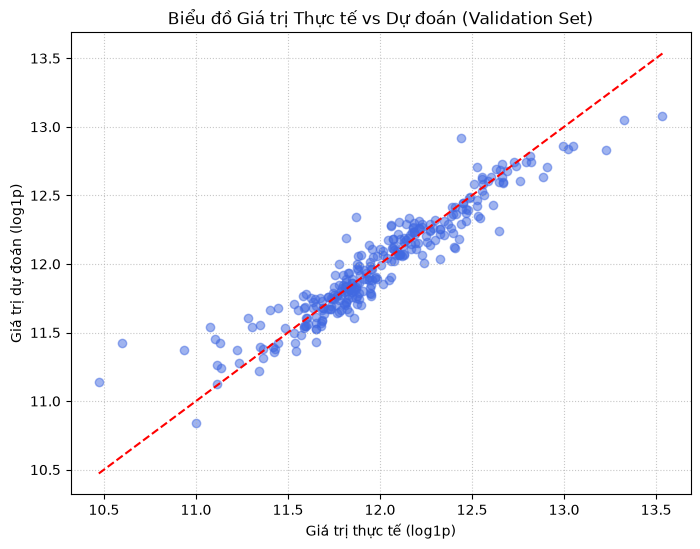

In [13]:
with torch.no_grad():
    y_pred_tensor = model(X_val_tensor).squeeze(-1)
    y_pred_log = y_pred_tensor.cpu().numpy()



log_rmse = root_mean_squared_error(y_val_log, y_pred_log)
log_mae = mean_absolute_error(y_val_log, y_pred_log)
r2 = r2_score(y_val_log, y_pred_log)

print("KẾT QUẢ ĐÁNH GIÁ MLP")
print(f"Validation log-RMSE : {log_rmse:.4f}")
print(f"Validation log-MAE  : {log_mae:.4f}")
print(f"Validation R2       : {r2:.4f}")

plt.figure(figsize=(8, 6))
plt.scatter(y_val_log, y_pred_log, alpha=0.5, color="royalblue")
plt.plot(
    [min(y_val_log), max(y_val_log)],
    [min(y_val_log), max(y_val_log)],
    color="red",
    linestyle="--",
)
plt.xlabel("Giá trị thực tế (log1p)")
plt.ylabel("Giá trị dự đoán (log1p)")
plt.title("Biểu đồ Giá trị Thực tế vs Dự đoán (Validation Set)")
plt.grid(True, linestyle=":", alpha=0.7)
plt.savefig("../outputs/figures/actual_vs_predicted_mlp.png")
plt.show()

## 4. Dự đoán Tập Test & Tạo file Submission
Sử dụng toàn bộ features của tập ẩn để dự đoán.

In [ ]:

X_test = test_df[features].values
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)

# 1. Dự đoán kết quả (đang ở thang đo logarit)
with torch.no_grad():
    test_preds_log = model(X_test_tensor).squeeze(-1).cpu().numpy()

# 2. BẮT BUỘC DÙNG expm1 để chuyển từ Logarit về Giá tiền thật
test_preds = np.expm1(test_preds_log)

# 3. Đảm bảo không có giá trị âm
test_preds = np.maximum(0, test_preds)

# Tạo DataFrame và xuất file
submission_df = pd.DataFrame({"Id": test_df["Id"].astype(int), "SalePrice": test_preds})
os.makedirs("../outputs/submissions", exist_ok=True)
submission_path = "../outputs/submissions/submission_mlp.csv"
submission_df.to_csv(submission_path, index=False)

print(f"File nộp bài đã được tạo thành công tại: {submission_path}")


File nộp bài đã được tạo thành công tại: ../outputs/submissions/submission_mlp.csv
